In [1]:
import sklearn

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_csv("titanic_train.csv")

In [3]:
df.shape

(891, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Initial observation:**
The age count is 714 but there are 891 rows, so there may be missing values. Also, the count for cabin is 204 and embarked 889, so there may be missing values.

In [6]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df.shape

(891, 12)

In [8]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
X = df[["Fare", "Age", "Pclass"]]
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)

In [10]:
len(X_train)

623

In [11]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X_train, y_train)
print(tree.score(X_test, y_test))

0.6940298507462687


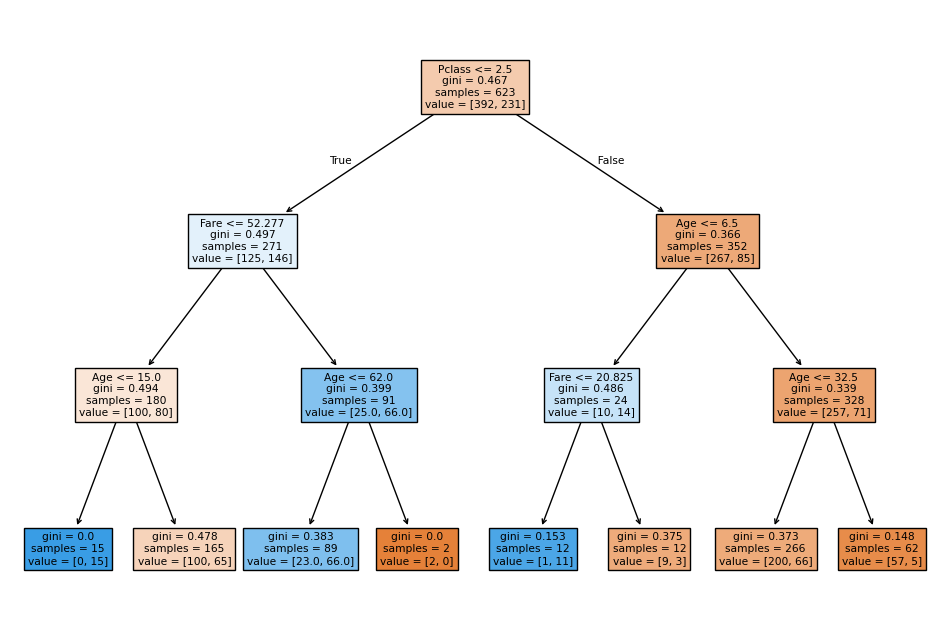

In [12]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize= (12,8))
plot_tree(tree, feature_names=X.columns, filled=True)
plt.show()

In [13]:
fitted_results = tree.predict(X_test)
results = X_test.copy()
results["Wrong"] = fitted_results !=y_test
results.groupby("Pclass")["Wrong"].mean()

Pclass
1    0.376623
2    0.423077
3    0.223022
Name: Wrong, dtype: float64

This model most often gets second class passengers wrong with the highest test error rate of 42.3%.

**Cleaning Log**

The age column had 177 missing values, I decided to replace the missing values with the median since it is less affected by extreme values.I retained all 891 passaengers.

https://github.com/jazzminowens/cs82a-portfolio